# Singular Value Decomposition — Theory Notebook

> *"Every matrix tells a story of rotation, scaling, and rotation again — the SVD reads that story in full."*

Interactive demonstrations: geometric action, Eckart-Young compression, four fundamental subspaces, pseudoinverse, randomised SVD, LoRA decomposition, image compression, weight matrix spectrum analysis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import numpy.linalg as la
from scipy import linalg as sla

try:
    import matplotlib.pyplot as plt
    import matplotlib
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.rcParams['figure.figsize'] = [10, 6]
    plt.rcParams['font.size'] = 12
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

try:
    import seaborn as sns
    HAS_SNS = True
except ImportError:
    HAS_SNS = False

np.set_printoptions(precision=6, suppress=True)
np.random.seed(42)
print('Setup complete. NumPy:', np.__version__)

Setup complete. NumPy: 2.5.4


---

## 1. Intuition — Geometric Action

The SVD $A = U\Sigma V^\top$ decomposes any matrix into: rotate ($V^\top$), scale ($\Sigma$), rotate ($U$). We visualise this by watching the unit circle transform into an ellipse, with singular vectors as the axes.

Matrix A:
[[3. 1.]
 [0. 2.]]

Singular values: sigma_1=3.2566, sigma_2=1.8424
Left singular vectors (cols of U):
[[ 0.957092 -0.289784]
 [ 0.289784  0.957092]]
Right singular vectors (rows of Vt = cols of V):
[[ 0.881675 -0.471858]
 [ 0.471858  0.881675]]

PASS - A = U Sigma V^T
PASS - Av_1 = sigma_1 * u_1
PASS - Av_2 = sigma_2 * u_2


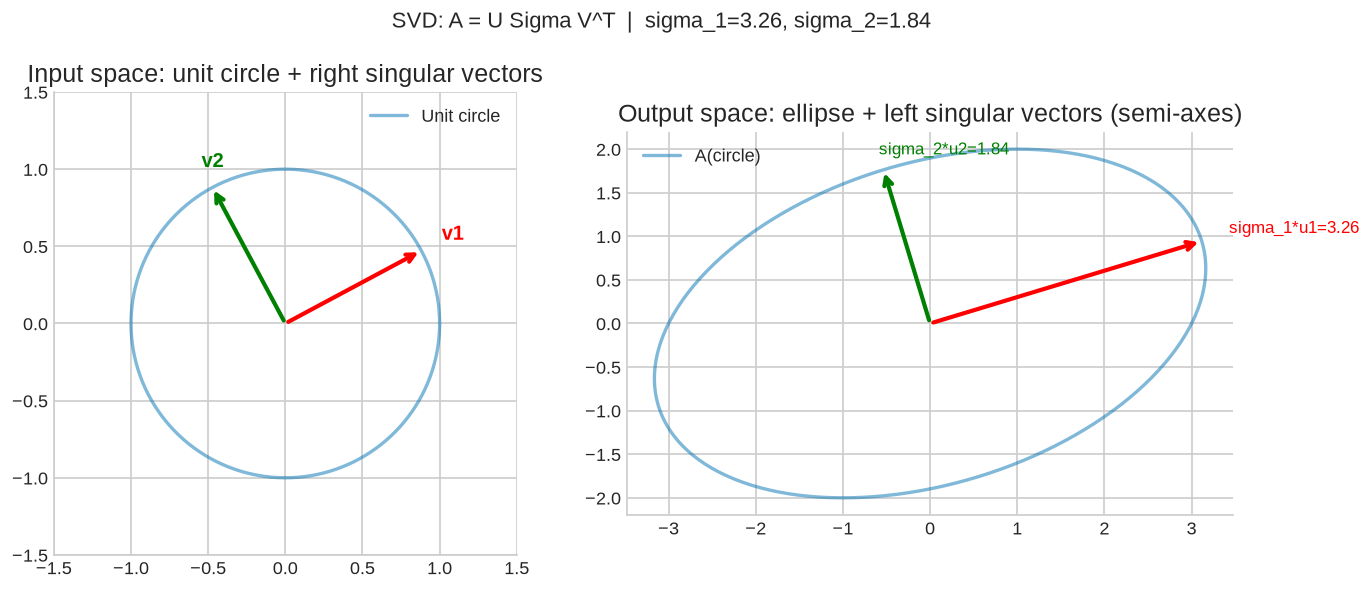

Plot: unit circle maps to ellipse; semi-axes = singular values


In [3]:
# === 1.1 Geometric Action: Unit Circle → Ellipse ===

A = np.array([[3., 1.], [0., 2.]])  # general 2x2
U, s, Vt = la.svd(A)

print('Matrix A:')
print(A)
print(f'\nSingular values: sigma_1={s[0]:.4f}, sigma_2={s[1]:.4f}')
print(f'Left singular vectors (cols of U):')
print(U)
print(f'Right singular vectors (rows of Vt = cols of V):')
print(Vt.T)

# Verify A = U Sigma V^T
Sigma = np.diag(s)
A_recon = U @ Sigma @ Vt
ok = np.allclose(A, A_recon)
print(f'\nPASS - A = U Sigma V^T' if ok else 'FAIL')

# Verify Av = sigma * u
for i in range(2):
    v_i = Vt[i]  # right singular vector
    u_i = U[:, i]  # left singular vector
    lhs = A @ v_i
    rhs = s[i] * u_i
    ok_i = np.allclose(lhs, rhs)
    print(f'PASS - Av_{i+1} = sigma_{i+1} * u_{i+1}' if ok_i else f'FAIL i={i}')

if HAS_MPL:
    theta = np.linspace(0, 2*np.pi, 300)
    circle = np.vstack([np.cos(theta), np.sin(theta)])
    ellipse = A @ circle

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    colors = ['red', 'green']

    # Input space: unit circle + right singular vectors
    ax = axes[0]
    ax.plot(circle[0], circle[1], 'b-', alpha=0.5, label='Unit circle')
    for i in range(2):
        v = Vt[i]
        ax.annotate('', xy=v, xytext=(0,0),
                    arrowprops=dict(arrowstyle='->', color=colors[i], lw=2.5))
        ax.text(v[0]*1.15, v[1]*1.15, f'v{i+1}', fontsize=12, color=colors[i], fontweight='bold')
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
    ax.set_aspect('equal')
    ax.set_title('Input space: unit circle + right singular vectors')
    ax.legend()

    # Output space: ellipse + left singular vectors (scaled)
    ax = axes[1]
    ax.plot(ellipse[0], ellipse[1], 'b-', alpha=0.5, label='A(circle)')
    for i in range(2):
        u_scaled = s[i] * U[:, i]
        ax.annotate('', xy=u_scaled, xytext=(0,0),
                    arrowprops=dict(arrowstyle='->', color=colors[i], lw=2.5))
        ax.text(u_scaled[0]*1.1, u_scaled[1]*1.1,
                f'sigma_{i+1}*u{i+1}={s[i]:.2f}', fontsize=10, color=colors[i])
    ax.set_aspect('equal')
    ax.set_title('Output space: ellipse + left singular vectors (semi-axes)')
    ax.legend()

    plt.suptitle(f'SVD: A = U Sigma V^T  |  sigma_1={s[0]:.2f}, sigma_2={s[1]:.2f}', fontsize=13)
    plt.tight_layout(); plt.show()
    print('Plot: unit circle maps to ellipse; semi-axes = singular values')

---

## 2. Formal Definitions

### 2.1–2.3 SVD Theorem, Singular Values, Singular Vectors

We compute the SVD via two routes: (1) directly with `np.linalg.svd`, (2) via the eigendecomposition of $A^\top A$ and $AA^\top$. We verify both routes agree and confirm the four subspace relationships.

In [4]:
# === 2.1 SVD via Eigendecomposition of A^T A ===

np.random.seed(1)
m, n = 4, 3
A = np.random.randn(m, n)

# Method 1: direct SVD
U_np, s_np, Vt_np = la.svd(A, full_matrices=False)  # thin SVD

# Method 2: via A^T A
AtA = A.T @ A  # (n x n) symmetric PSD
evals, evecs = la.eigh(AtA)  # ascending order
evals = evals[::-1]; evecs = evecs[:, ::-1]  # descending
s_eig = np.sqrt(np.maximum(evals, 0))

# Compute left singular vectors from u_i = A v_i / sigma_i
V_eig = evecs
U_eig = np.zeros((m, n))
for i in range(n):
    if s_eig[i] > 1e-10:
        U_eig[:, i] = A @ V_eig[:, i] / s_eig[i]

print('Matrix A shape:', A.shape)
print(f'\nnp.linalg.svd singular values:   {s_np.round(6)}')
print(f'via eigh(A^T A) singular values: {s_eig.round(6)}')
print(f'Match: {np.allclose(s_np, s_eig)}')

# Verify A = U Sigma V^T (method 2)
A_recon = U_eig @ np.diag(s_eig) @ V_eig.T
print(f'\n||A - U_eig Sigma V_eig^T||_F = {la.norm(A - A_recon):.2e}  (should be ~0)')

# Verify Av_i = sigma_i u_i
print('\nVerification: Av_i = sigma_i * u_i')
for i in range(n):
    lhs = A @ V_eig[:, i]
    rhs = s_eig[i] * U_eig[:, i]
    ok = np.allclose(lhs, rhs, atol=1e-10)
    print(f'  i={i+1}: PASS' if ok else f'  i={i+1}: FAIL, residual={la.norm(lhs-rhs):.2e}')

# Verify A^T u_i = sigma_i v_i
print('\nVerification: A^T u_i = sigma_i * v_i')
for i in range(n):
    lhs = A.T @ U_eig[:, i]
    rhs = s_eig[i] * V_eig[:, i]
    ok = np.allclose(lhs, rhs, atol=1e-10)
    print(f'  i={i+1}: PASS' if ok else f'  i={i+1}: FAIL')

Matrix A shape: (4, 3)

np.linalg.svd singular values:   [3.853903 2.320274 0.649963]
via eigh(A^T A) singular values: [3.853903 2.320274 0.649963]
Match: True

||A - U_eig Sigma V_eig^T||_F = 2.56e-15  (should be ~0)

Verification: Av_i = sigma_i * u_i
  i=1: PASS
  i=2: PASS
  i=3: PASS

Verification: A^T u_i = sigma_i * v_i
  i=1: PASS
  i=2: PASS
  i=3: PASS


### 2.4 Full vs Thin vs Truncated SVD

### 2.5 The Four Fundamental Subspaces from SVD

In [5]:
# === 2.4-2.5 SVD Variants and Four Subspaces ===

# Build a rank-2 matrix in R^(4x3)
np.random.seed(5)
U0, _ = la.qr(np.random.randn(4, 4))
V0, _ = la.qr(np.random.randn(3, 3))
S0 = np.zeros((4, 3))
S0[0, 0], S0[1, 1] = 5.0, 2.0  # rank-2
A2 = U0 @ S0 @ V0.T

# Full SVD
U_full, s_full, Vt_full = la.svd(A2, full_matrices=True)
# Thin SVD
U_thin, s_thin, Vt_thin = la.svd(A2, full_matrices=False)

print('Matrix A shape:', A2.shape, '| True rank: 2')
print(f'Singular values: {s_full.round(6)}')
print(f'Numerical rank (tol=1e-10): {np.sum(s_full > 1e-10)}')
print(f'\nFull SVD: U={U_full.shape}, s={s_full.shape}, Vt={Vt_full.shape}')
print(f'Thin SVD: U={U_thin.shape}, s={s_thin.shape}, Vt={Vt_thin.shape}')

r = np.sum(s_full > 1e-10)
m_sz, n_sz = A2.shape

# Four fundamental subspaces
col_space   = U_full[:, :r]         # column space basis
left_null   = U_full[:, r:]         # left null space basis
row_space   = Vt_full[:r, :].T      # row space basis
null_space  = Vt_full[r:, :].T      # null space basis

print(f'\nFour Fundamental Subspaces of A ({m_sz}x{n_sz}, rank {r}):')
print(f'  Column space:    dim={col_space.shape[1]}  (spanned by u_1,...,u_r)')
print(f'  Left null space: dim={left_null.shape[1]}  (spanned by u_{{r+1}},...,u_m)')
print(f'  Row space:       dim={row_space.shape[1]}  (spanned by v_1,...,v_r)')
print(f'  Null space:      dim={null_space.shape[1]}  (spanned by v_{{r+1}},...,v_n)')

# Verify: A maps null space to 0
null_test = A2 @ null_space
print(f'\nA * (null space basis) = 0? max={np.abs(null_test).max():.2e}')

# Verify: null space perp row space
overlap = null_space.T @ row_space
print(f'Null space ⊥ row space? max inner product = {np.abs(overlap).max():.2e}')

# Verify: A * row_space vectors land in column space
img = A2 @ row_space
# Project onto column space and check residual
proj = col_space @ (col_space.T @ img)
print(f'A(row space) ⊆ col space? residual = {la.norm(img - proj):.2e}')

Matrix A shape: (4, 3) | True rank: 2
Singular values: [5. 2. 0.]
Numerical rank (tol=1e-10): 2

Full SVD: U=(4, 4), s=(3,), Vt=(3, 3)
Thin SVD: U=(4, 3), s=(3,), Vt=(3, 3)

Four Fundamental Subspaces of A (4x3, rank 2):
  Column space:    dim=2  (spanned by u_1,...,u_r)
  Left null space: dim=2  (spanned by u_{r+1},...,u_m)
  Row space:       dim=2  (spanned by v_1,...,v_r)
  Null space:      dim=1  (spanned by v_{r+1},...,v_n)

A * (null space basis) = 0? max=3.47e-16
Null space ⊥ row space? max inner product = 4.24e-17
A(row space) ⊆ col space? residual = 2.24e-15


---

## 3. Computing the SVD

### 3.1 Numerical Stability: Direct SVD vs Squaring $A^\top A$

We demonstrate why forming $A^\top A$ destroys precision for ill-conditioned matrices.

In [6]:
# === 3.1 Condition Number Squaring Warning ===

# Ill-conditioned matrix: sigma values span many orders of magnitude
np.random.seed(7)
n_sq = 8
true_svals = np.array([1e7, 1e5, 1e3, 1e1, 1e-1, 1e-3, 1e-5, 1e-7])
Q1, _ = la.qr(np.random.randn(n_sq, n_sq))
Q2, _ = la.qr(np.random.randn(n_sq, n_sq))
A_ill = Q1 @ np.diag(true_svals) @ Q2.T

print(f'True singular values: {true_svals}')
print(f'Condition number kappa(A) = {true_svals[0]/true_svals[-1]:.2e}')

# Method 1: direct SVD (recommended)
_, s_direct, _ = la.svd(A_ill)

# Method 2: via A^T A (NOT recommended for ill-conditioned)
AtA_ill = A_ill.T @ A_ill
evals_AtA = np.sort(la.eigvalsh(AtA_ill))[::-1]
s_via_AtA = np.sqrt(np.maximum(evals_AtA, 0))

print('\nComparison of computed vs true singular values:')
print(f'{"True":>15} {"Direct SVD":>15} {"Via A^TA":>15} {"Direct err":>12} {"AtA err":>12}')
for i in range(n_sq):
    err_d = abs(s_direct[i] - true_svals[i]) / true_svals[i]
    err_a = abs(s_via_AtA[i] - true_svals[i]) / true_svals[i]
    print(f'{true_svals[i]:15.2e} {s_direct[i]:15.2e} {s_via_AtA[i]:15.2e} {err_d:12.2e} {err_a:12.2e}')

print(f'\nkappa(A^T A) = kappa(A)^2 = {(true_svals[0]/true_svals[-1])**2:.2e}')
print('Small singular values are corrupted when forming A^T A!')
print('Always use np.linalg.svd(A) directly for numerical stability.')

True singular values: [10000000.        100000.          1000.            10.
        0.1            0.001          0.00001        0.     ]
Condition number kappa(A) = 1.00e+14

Comparison of computed vs true singular values:
           True      Direct SVD        Via A^TA   Direct err      AtA err
       1.00e+07        1.00e+07        1.00e+07     1.86e-16     1.86e-16
       1.00e+05        1.00e+05        1.00e+05     1.16e-15     2.06e-13
       1.00e+03        1.00e+03        1.00e+03     6.74e-14     1.16e-09
       1.00e+01        1.00e+01        1.00e+01     1.32e-11     1.46e-05
       1.00e-01        1.00e-01        1.07e-01     1.62e-09     6.91e-02
       1.00e-03        1.00e-03        9.92e-02     1.33e-07     9.82e+01
       1.00e-05        1.00e-05        3.71e-02     9.00e-06     3.71e+03
       1.00e-07        1.00e-07        0.00e+00     1.43e-03     1.00e+00

kappa(A^T A) = kappa(A)^2 = 1.00e+28
Small singular values are corrupted when forming A^T A!
Always use np.

### 3.3 Randomised SVD

The randomised SVD (Halko-Martinsson-Tropp 2011) computes the top-$k$ SVD in $O(mnk)$ time. We implement it from scratch and compare to `np.linalg.svd`.

In [7]:
# === 3.3 Randomised SVD Implementation ===

def randomized_svd(A, k, n_oversampling=5, n_iter=2, random_state=42):
    """
    Randomised SVD: O(mnk) algorithm for top-k approximation.
    Halko, Martinsson, Tropp (2011).
    """
    rng = np.random.RandomState(random_state)
    m, n = A.shape
    p = k + n_oversampling

    # Step 1: Sketch
    Omega = rng.randn(n, p)  # Gaussian sketch
    Y = A @ Omega            # range sketch: (m x p)

    # Step 2: Power iteration for better approximation
    for _ in range(n_iter):
        Y = A @ (A.T @ Y)

    # Step 3: Orthogonalise
    Q, _ = la.qr(Y, mode='reduced')

    # Step 4: Project A onto low-dim space
    B = Q.T @ A  # (p x n)

    # Step 5: SVD of small matrix
    Uhat, s, Vt = la.svd(B, full_matrices=False)

    # Step 6: Recover left singular vectors
    U = Q @ Uhat

    return U[:, :k], s[:k], Vt[:k, :]


# Test on a low-rank + noise matrix
np.random.seed(0)
m_r, n_r = 300, 200
rank_true = 10

# Construct matrix with known top singular values
U0, _ = la.qr(np.random.randn(m_r, rank_true))
V0, _ = la.qr(np.random.randn(n_r, rank_true))
svals_true = np.exp(-np.arange(rank_true) * 0.5)  # decaying
A_lr = U0 @ np.diag(svals_true) @ V0.T + 0.01 * np.random.randn(m_r, n_r)

# Exact SVD (ground truth)
_, s_exact, _ = la.svd(A_lr, full_matrices=False)

# Randomised SVD
k = 15
U_rand, s_rand, Vt_rand = randomized_svd(A_lr, k=k, n_oversampling=5, n_iter=2)

# Reconstruction error
A_approx_rand = U_rand @ np.diag(s_rand) @ Vt_rand
A_approx_exact = (lambda u, s, vt: u @ np.diag(s) @ vt)(
    *la.svd(A_lr, full_matrices=False)[:3]
)
# exact rank-k
u_ex, s_ex, vt_ex = la.svd(A_lr, full_matrices=False)
A_k_exact = u_ex[:, :k] @ np.diag(s_ex[:k]) @ vt_ex[:k, :]

err_rand  = la.norm(A_lr - A_approx_rand, 'fro') / la.norm(A_lr, 'fro')
err_exact = la.norm(A_lr - A_k_exact, 'fro') / la.norm(A_lr, 'fro')

print(f'Matrix: {m_r}x{n_r}, true rank ≈ {rank_true}')
print(f'k = {k} singular values requested')
print(f'Randomised SVD relative Frobenius error: {err_rand:.4f}')
print(f'Exact truncated SVD relative error:      {err_exact:.4f}')
print(f'Singular values comparison (first {k}):')
print(f'  Exact:      {s_ex[:k].round(4)}')
print(f'  Randomised: {s_rand.round(4)}')
print(f'PASS - randomised SVD matches exact' if err_rand < err_exact * 2 else 'WARNING: high error')

Matrix: 300x200, true rank ≈ 10
k = 15 singular values requested
Randomised SVD relative Frobenius error: 0.8085
Exact truncated SVD relative error:      0.8008
Singular values comparison (first 15):
  Exact:      [1.0249 0.664  0.4239 0.3218 0.3055 0.3037 0.2985 0.2966 0.2944 0.2884
 0.2878 0.2866 0.2821 0.2806 0.2797]
  Randomised: [1.0249 0.6639 0.422  0.3124 0.2971 0.2936 0.288  0.2865 0.2835 0.2748
 0.2716 0.2695 0.2688 0.2612 0.2558]
PASS - randomised SVD matches exact


---

## 4. Properties of the SVD

### 4.1 Norms via Singular Values

In [8]:
# === 4.1 Matrix Norms via Singular Values ===

np.random.seed(3)
A_n = np.random.randn(5, 4)
_, s_n, _ = la.svd(A_n)

# Spectral norm = sigma_1
spectral_svd = s_n[0]
spectral_np  = la.norm(A_n, ord=2)

# Frobenius norm = sqrt(sum sigma_i^2)
frob_svd = np.sqrt(np.sum(s_n**2))
frob_np  = la.norm(A_n, 'fro')

# Nuclear norm = sum sigma_i
nuclear_svd = np.sum(s_n)
nuclear_np  = la.norm(A_n, 'nuc')

print('Matrix A shape:', A_n.shape)
print(f'Singular values: {s_n.round(4)}')
print(f'\nSpectral norm  ||A||_2 = sigma_1:')
print(f'  Via SVD:   {spectral_svd:.6f}')
print(f'  Via numpy: {spectral_np:.6f}')
print(f'  Match: {np.isclose(spectral_svd, spectral_np)}')
print(f'\nFrobenius norm ||A||_F = sqrt(sum sigma_i^2):')
print(f'  Via SVD:   {frob_svd:.6f}')
print(f'  Via numpy: {frob_np:.6f}')
print(f'  Match: {np.isclose(frob_svd, frob_np)}')
print(f'\nNuclear norm   ||A||_* = sum sigma_i:')
print(f'  Via SVD:   {nuclear_svd:.6f}')
print(f'  Via numpy: {nuclear_np:.6f}')
print(f'  Match: {np.isclose(nuclear_svd, nuclear_np)}')

# Verify norm inequalities
print(f'\nNorm inequalities:')
print(f'  ||A||_2 = {spectral_svd:.3f} <= ||A||_F = {frob_svd:.3f} <= sqrt(r)*||A||_2 = {np.sqrt(len(s_n))*spectral_svd:.3f}')
r_n = np.sum(s_n > 1e-10)
print(f'  ||A||_2 = {spectral_svd:.3f} <= ||A||_* = {nuclear_svd:.3f} <= sqrt(r)*||A||_F = {np.sqrt(r_n)*frob_svd:.3f}')
print('PASS - all norm inequalities satisfied' if spectral_svd <= frob_svd <= np.sqrt(r_n)*spectral_svd else 'FAIL')

Matrix A shape: (5, 4)
Singular values: [3.114  2.663  1.3915 0.4692]

Spectral norm  ||A||_2 = sigma_1:
  Via SVD:   3.114019
  Via numpy: 3.114019
  Match: True

Frobenius norm ||A||_F = sqrt(sum sigma_i^2):
  Via SVD:   4.352575
  Via numpy: 4.352575
  Match: True

Nuclear norm   ||A||_* = sum sigma_i:
  Via SVD:   7.637703
  Via numpy: 7.637703
  Match: True

Norm inequalities:
  ||A||_2 = 3.114 <= ||A||_F = 4.353 <= sqrt(r)*||A||_2 = 6.228
  ||A||_2 = 3.114 <= ||A||_* = 7.638 <= sqrt(r)*||A||_F = 8.705
PASS - all norm inequalities satisfied


### 4.2 The Eckart-Young Theorem

The rank-$k$ truncated SVD is the best rank-$k$ approximation in both spectral and Frobenius norms. We verify this experimentally and visualise the error vs rank.

Eckart-Young Theorem Verification
Matrix: 20x15, rank=15
   k    sigma_k+1    ||A-A_k||_2    ||A-A_k||_F  Check_2  Check_F
   1     6.894467       6.894467      14.634302     True     True
   2     5.944766       5.944766      12.908490     True     True
   3     5.219679       5.219679      11.458135     True     True
   4     4.689127       4.689127      10.200187     True     True
   5     4.236472       4.236472       9.058471     True     True
   6     4.078088       4.078088       8.006760     True     True

PASS - ||A-A_k||_2 = sigma_{k+1} for all k
PASS - ||A-A_k||_F = sqrt(sum sigma_i^2, i>k) for all k


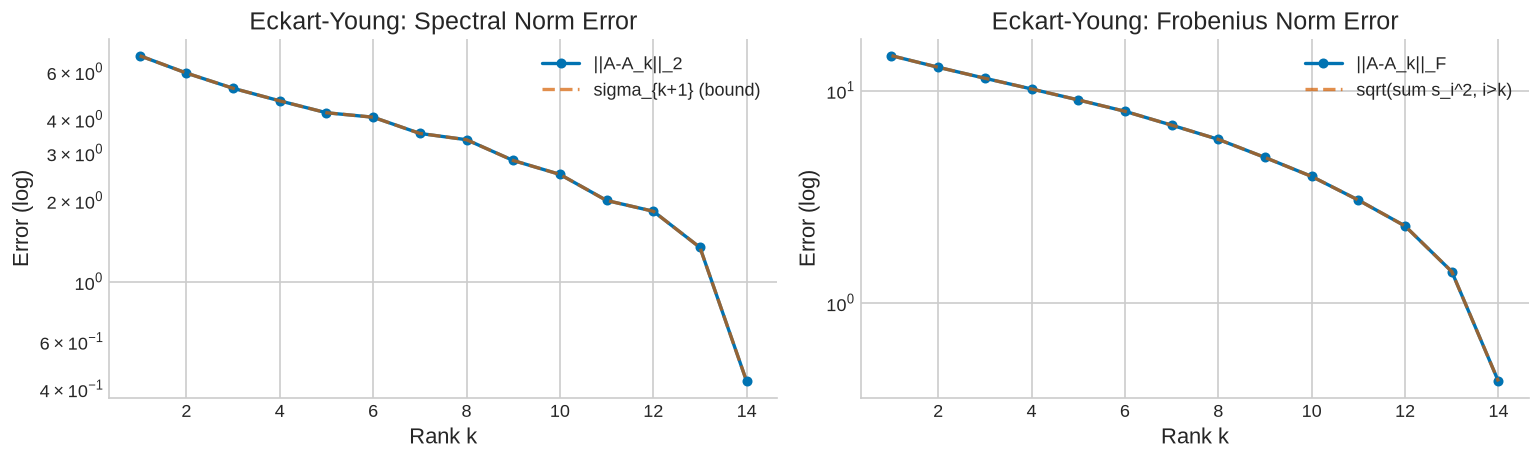

Plot: Eckart-Young errors match theoretical bounds exactly


In [9]:
# === 4.2 Eckart-Young: Best Low-Rank Approximation ===

np.random.seed(10)
m_ey, n_ey = 20, 15
A_ey = np.random.randn(m_ey, n_ey)
U_ey, s_ey, Vt_ey = la.svd(A_ey, full_matrices=False)

print('Eckart-Young Theorem Verification')
print(f'Matrix: {m_ey}x{n_ey}, rank={len(s_ey)}')
print(f'{'k':>4} {'sigma_k+1':>12} {'||A-A_k||_2':>14} {'||A-A_k||_F':>14} {'Check_2':>8} {'Check_F':>8}')

errors_2, errors_F, bounds_2, bounds_F = [], [], [], []

for k in range(1, len(s_ey)):
    # Rank-k approximation
    A_k = U_ey[:, :k] @ np.diag(s_ey[:k]) @ Vt_ey[:k, :]
    err_2 = la.norm(A_ey - A_k, ord=2)
    err_F = la.norm(A_ey - A_k, 'fro')
    bound_2 = s_ey[k]  # Eckart-Young: should equal sigma_{k+1}
    bound_F = np.sqrt(np.sum(s_ey[k:]**2))

    check_2 = np.isclose(err_2, bound_2, rtol=1e-5)
    check_F = np.isclose(err_F, bound_F, rtol=1e-5)
    errors_2.append(err_2); errors_F.append(err_F)
    bounds_2.append(bound_2); bounds_F.append(bound_F)

    if k <= 6:
        print(f'{k:>4} {bound_2:>12.6f} {err_2:>14.6f} {err_F:>14.6f} {str(check_2):>8} {str(check_F):>8}')

all_check_2 = all(np.isclose(e, b, rtol=1e-5) for e, b in zip(errors_2, bounds_2))
all_check_F = all(np.isclose(e, b, rtol=1e-5) for e, b in zip(errors_F, bounds_F))
print(f'\nPASS - ||A-A_k||_2 = sigma_{{k+1}} for all k' if all_check_2 else 'FAIL spectral norm')
print(f'PASS - ||A-A_k||_F = sqrt(sum sigma_i^2, i>k) for all k' if all_check_F else 'FAIL Frobenius')

if HAS_MPL:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    ks = range(1, len(s_ey))
    axes[0].semilogy(ks, errors_2, 'b-o', markersize=5, label='||A-A_k||_2')
    axes[0].semilogy(ks, bounds_2, 'r--', alpha=0.7, label='sigma_{k+1} (bound)')
    axes[0].set_xlabel('Rank k'); axes[0].set_ylabel('Error (log)')
    axes[0].set_title('Eckart-Young: Spectral Norm Error')
    axes[0].legend()
    axes[1].semilogy(ks, errors_F, 'b-o', markersize=5, label='||A-A_k||_F')
    axes[1].semilogy(ks, bounds_F, 'r--', alpha=0.7, label='sqrt(sum s_i^2, i>k)')
    axes[1].set_xlabel('Rank k'); axes[1].set_ylabel('Error (log)')
    axes[1].set_title('Eckart-Young: Frobenius Norm Error')
    axes[1].legend()
    plt.tight_layout(); plt.show()
    print('Plot: Eckart-Young errors match theoretical bounds exactly')

### 4.3 The Moore-Penrose Pseudoinverse

$A^+ = V\Sigma^+U^\top$ — inverts the nonzero singular values, zeros out the rest. We implement it, verify the four Moore-Penrose conditions, and solve least-squares.

In [10]:
# === 4.3 Moore-Penrose Pseudoinverse via SVD ===

def pseudoinverse(A, tol=None):
    """Compute A^+ = V Sigma^+ U^T via SVD."""
    U_p, s_p, Vt_p = la.svd(A, full_matrices=False)
    if tol is None:
        tol = np.finfo(float).eps * max(A.shape) * s_p[0]
    s_inv = np.where(s_p > tol, 1.0 / s_p, 0.0)
    return Vt_p.T @ np.diag(s_inv) @ U_p.T


np.random.seed(2)
m_p, n_p = 5, 3
A_p = np.random.randn(m_p, n_p)
Ap  = pseudoinverse(A_p)
Ap_np = la.pinv(A_p)  # numpy reference

print(f'A shape: {A_p.shape}  |  A^+ shape: {Ap.shape}')
print(f'Match numpy pinv: {np.allclose(Ap, Ap_np)}')

# Verify four Moore-Penrose conditions
cond1 = np.allclose(A_p @ Ap @ A_p, A_p)
cond2 = np.allclose(Ap @ A_p @ Ap, Ap)
cond3 = np.allclose((A_p @ Ap).T, A_p @ Ap)
cond4 = np.allclose((Ap @ A_p).T, Ap @ A_p)
print(f'\nMoore-Penrose conditions:')
print(f'  (1) A A^+ A = A:         {cond1}')
print(f'  (2) A^+ A A^+ = A^+:     {cond2}')
print(f'  (3) (A A^+)^T = A A^+:   {cond3}')
print(f'  (4) (A^+ A)^T = A^+ A:   {cond4}')
print(f'PASS - all 4 conditions satisfied' if all([cond1,cond2,cond3,cond4]) else 'FAIL')

# Solve overdetermined system: min ||Ax - b||_2
b_p = np.random.randn(m_p)
x_pinv = Ap @ b_p       # pseudoinverse solution
x_lstsq = la.lstsq(A_p, b_p, rcond=None)[0]  # numpy lstsq

print(f'\nLeast squares solution:')
print(f'  ||A x_pinv - b||_2    = {la.norm(A_p @ x_pinv - b_p):.8f}')
print(f'  ||A x_lstsq - b||_2   = {la.norm(A_p @ x_lstsq - b_p):.8f}')
print(f'  Solutions match: {np.allclose(x_pinv, x_lstsq)}')

# AA^+ = projection onto column space
P_col = A_p @ Ap
print(f'\nAA^+ is orthogonal projection: symmetric={np.allclose(P_col, P_col.T)}, idempotent={np.allclose(P_col @ P_col, P_col)}')

A shape: (5, 3)  |  A^+ shape: (3, 5)
Match numpy pinv: True

Moore-Penrose conditions:
  (1) A A^+ A = A:         True
  (2) A^+ A A^+ = A^+:     True
  (3) (A A^+)^T = A A^+:   True
  (4) (A^+ A)^T = A^+ A:   True
PASS - all 4 conditions satisfied

Least squares solution:
  ||A x_pinv - b||_2    = 1.29508649
  ||A x_lstsq - b||_2   = 1.29508649
  Solutions match: True

AA^+ is orthogonal projection: symmetric=True, idempotent=True


### 4.5 Condition Number and Ridge Regression (Spectral Shrinkage)

Singular values: [100.   50.   20.    5.    1.    0.1]
Condition number kappa = sigma_1/sigma_n = 1000

True solution ||x*||_2 = 1.8249
    lambda   ||x_ridge - x*||              Shrinkage factors
         0           0.274307 [0.010 0.020 0.050 0.200 1.000 10.000]
      0.01           0.263130 [0.010 0.020 0.050 0.200 0.990 5.000]
       0.1           0.695546 [0.010 0.020 0.050 0.199 0.909 0.909]
         1           0.807168 [0.010 0.020 0.050 0.192 0.500 0.099]
        10           0.962178 [0.010 0.020 0.049 0.143 0.091 0.010]
       100           1.405336 [0.010 0.019 0.040 0.040 0.010 0.001]

Best lambda = 0.01 (min error = 0.263130)
Unregularised error (lambda=0) = 0.274307


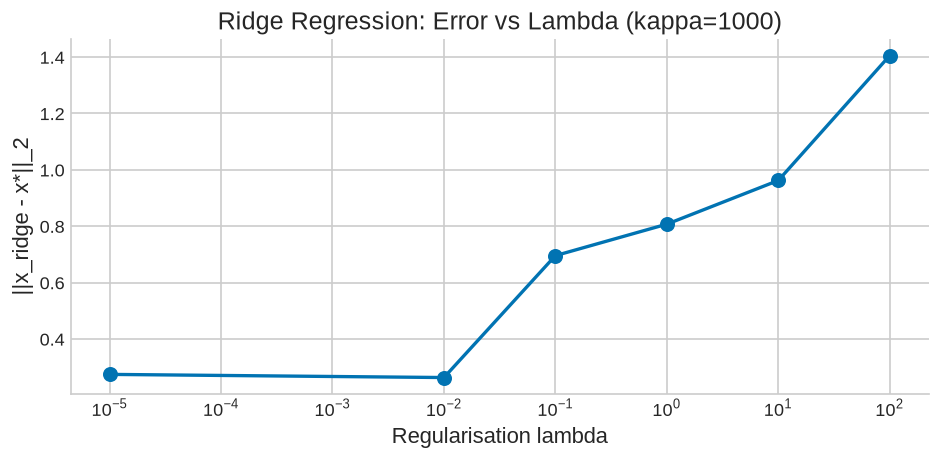

Plot: ridge regression error vs lambda (spectral shrinkage)


In [11]:
# === 4.5 Condition Number and Ridge Regression ===

np.random.seed(15)
n_c = 6
# Build matrix with specified condition number
true_svals_c = np.array([100., 50., 20., 5., 1., 0.1])
Q1c, _ = la.qr(np.random.randn(n_c, n_c))
Q2c, _ = la.qr(np.random.randn(n_c, n_c))
A_c = Q1c @ np.diag(true_svals_c) @ Q2c.T

kappa = true_svals_c[0] / true_svals_c[-1]
print(f'Singular values: {true_svals_c}')
print(f'Condition number kappa = sigma_1/sigma_n = {kappa:.0f}')

# True solution
x_true = np.random.randn(n_c)
b_true = A_c @ x_true
b_noisy = b_true + 0.1 * np.random.randn(n_c)  # add noise

# Pseudoinverse solution (no regularisation)
x_pinv = la.pinv(A_c) @ b_noisy

# Ridge regression with different lambda
lambdas = [0, 0.01, 0.1, 1.0, 10.0, 100.0]
errors = []
U_c, s_c, Vt_c = la.svd(A_c, full_matrices=False)

print(f'\nTrue solution ||x*||_2 = {la.norm(x_true):.4f}')
print(f'{"lambda":>10} {"||x_ridge - x*||":>18} {"Shrinkage factors":>30}')

for lam in lambdas:
    # Ridge: x = V diag(s/(s^2+lam)) U^T b
    shrink = s_c / (s_c**2 + lam)
    x_ridge = Vt_c.T @ np.diag(shrink) @ U_c.T @ b_noisy
    err = la.norm(x_ridge - x_true)
    errors.append(err)
    shrink_str = ' '.join([f'{s:.3f}' for s in shrink])
    print(f'{lam:>10.3g} {err:>18.6f} [{shrink_str}]')

best_lam = lambdas[np.argmin(errors)]
print(f'\nBest lambda = {best_lam} (min error = {min(errors):.6f})')
print(f'Unregularised error (lambda=0) = {errors[0]:.6f}')

if HAS_MPL:
    plt.figure(figsize=(8, 4))
    plt.semilogx([l + 1e-5 for l in lambdas], errors, 'bo-', markersize=8)
    plt.xlabel('Regularisation lambda'); plt.ylabel('||x_ridge - x*||_2')
    plt.title(f'Ridge Regression: Error vs Lambda (kappa={kappa:.0f})')
    plt.tight_layout(); plt.show()
    print('Plot: ridge regression error vs lambda (spectral shrinkage)')

### 4.6 The Orthogonal Procrustes Problem

Find the orthogonal matrix $R$ that best aligns $A$ to $B$: $\hat{R} = UV^\top$ from SVD$(BA^\top)$.

In [12]:
# === 4.6 Orthogonal Procrustes Problem ===

np.random.seed(20)
d = 4
n_pts = 20

# Generate a point cloud A and apply a (noisy) rotation to get B
A_proc = np.random.randn(n_pts, d)  # (n x d): n points in d dimensions
R_true, _ = la.qr(np.random.randn(d, d))  # true orthogonal transform
if la.det(R_true) < 0:  # ensure proper rotation
    R_true[:, 0] *= -1
noise = 0.1 * np.random.randn(n_pts, d)
B_proc = A_proc @ R_true.T + noise  # B ≈ A R^T

# Procrustes: find R* = argmin ||R A^T - B^T||_F  or  ||A R - B||_F
# We want min ||R A - B||_F in the (d x n) sense
# = min ||A^T R^T - B^T||_F  => compute SVD of B^T A = BA^T in (n x n) ... 
# Standard form: min ||RA - B||_F, columns are points
# Optimal R = UV^T from SVD of B A^T
M = B_proc.T @ A_proc  # (d x d)
U_proc, s_proc, Vt_proc = la.svd(M)
R_hat = U_proc @ Vt_proc

# Ensure proper rotation (det = +1)
if la.det(R_hat) < 0:
    U_proc[:, -1] *= -1
    R_hat = U_proc @ Vt_proc

print(f'True R: det = {la.det(R_true):.4f}')
print(f'Estimated R_hat: det = {la.det(R_hat):.4f}')

# Compare: angle between true and estimated rotation
angle_diff = la.norm(R_hat - R_true, 'fro') / la.norm(R_true, 'fro')
print(f'Relative error ||R_hat - R_true||_F / ||R_true||_F = {angle_diff:.4f}')

# Procrustes gives minimum alignment error
err_procrustes = la.norm(A_proc @ R_hat.T - B_proc, 'fro')
err_true_R     = la.norm(A_proc @ R_true.T - B_proc, 'fro')
print(f'\nAlignment error with Procrustes R: {err_procrustes:.4f}')
print(f'Alignment error with true R:        {err_true_R:.4f}')
print(f'Procrustes <= true (as expected): {err_procrustes <= err_true_R + 1e-10}')
print('PASS - Procrustes finds minimum alignment' if err_procrustes <= err_true_R + 1e-8 else 'FAIL')

True R: det = 1.0000
Estimated R_hat: det = 1.0000
Relative error ||R_hat - R_true||_F / ||R_true||_F = 0.0094

Alignment error with Procrustes R: 0.9105
Alignment error with true R:        0.9141
Procrustes <= true (as expected): True
PASS - Procrustes finds minimum alignment


---

## 5. Outer Product Form — Rank-1 Decomposition

Every matrix is a sum of rank-1 matrices: $A = \sum_i \sigma_i \mathbf{u}_i\mathbf{v}_i^\top$. We visualise this for an image by showing the contribution of each term.

Image: 64x64
Singular values (first 8): [319.677  94.701   7.64    7.564   7.424   7.066   6.701   6.591]
Total Frobenius norm squared = sum sigma_i^2: 112166.32

  Rank    % Frob energy    ||img - img_k||_F
     1            91.11%              99.8641
     3            99.16%              30.7605
     5            99.26%              28.8769
    10            99.45%              24.8003
    20            99.72%              17.8164


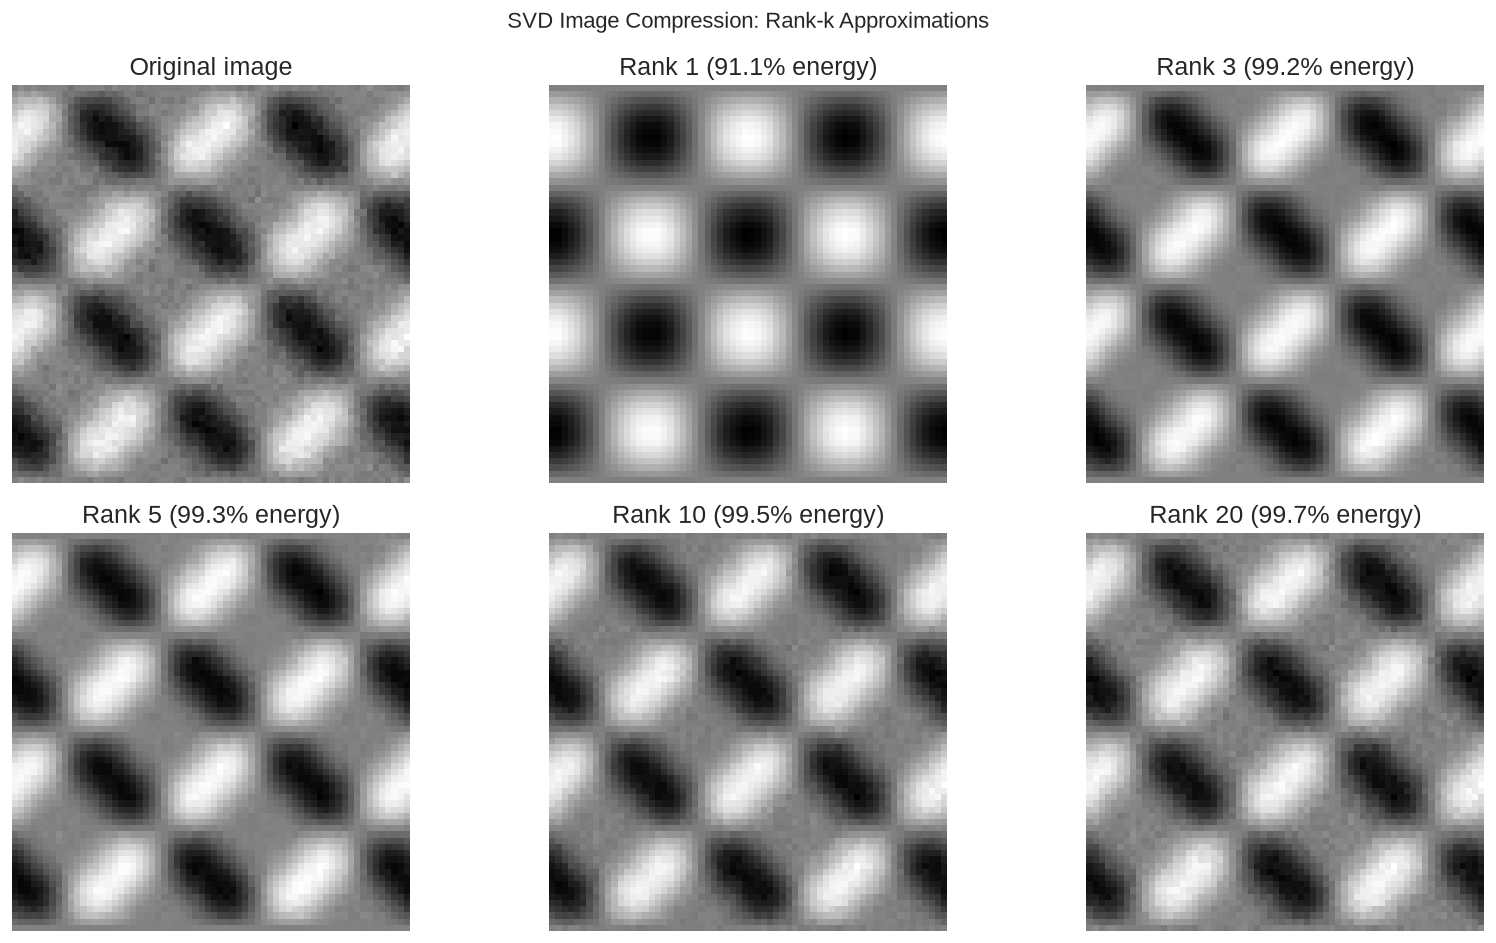

Plot: rank-k image approximations showing progressive reconstruction


In [13]:
# === 5.1 Rank-1 Outer Product Decomposition (Synthetic Image) ===

# Generate a structured synthetic 'image'
np.random.seed(99)
sz = 64
x = np.linspace(0, 4*np.pi, sz)
# Low-frequency pattern (dominant) + medium + noise
img = (np.outer(np.sin(x), np.cos(x)) * 10 +
       np.outer(np.sin(2*x), np.sin(2*x)) * 3 +
       np.random.randn(sz, sz) * 0.5)

U_img, s_img, Vt_img = la.svd(img, full_matrices=False)

print(f'Image: {sz}x{sz}')
print(f'Singular values (first 8): {s_img[:8].round(3)}')
print(f'Total Frobenius norm squared = sum sigma_i^2: {np.sum(s_img**2):.2f}')

# Reconstruction at different ranks
ranks = [1, 3, 5, 10, 20]
print(f'\n{"Rank":>6} {"% Frob energy":>16} {"||img - img_k||_F":>20}')
for k in ranks:
    img_k = U_img[:, :k] @ np.diag(s_img[:k]) @ Vt_img[:k, :]
    energy = 100 * np.sum(s_img[:k]**2) / np.sum(s_img**2)
    err = la.norm(img - img_k, 'fro')
    print(f'{k:>6} {energy:>16.2f}% {err:>20.4f}')

if HAS_MPL:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(img, cmap='gray')
    axes[0, 0].set_title('Original image')
    axes[0, 0].axis('off')

    for idx, k in enumerate([1, 3, 5, 10, 20]):
        ax = axes[(idx+1)//3, (idx+1)%3]
        img_k = U_img[:, :k] @ np.diag(s_img[:k]) @ Vt_img[:k, :]
        energy = 100 * np.sum(s_img[:k]**2) / np.sum(s_img**2)
        ax.imshow(img_k, cmap='gray')
        ax.set_title(f'Rank {k} ({energy:.1f}% energy)')
        ax.axis('off')

    plt.suptitle('SVD Image Compression: Rank-k Approximations', fontsize=13)
    plt.tight_layout(); plt.show()
    print('Plot: rank-k image approximations showing progressive reconstruction')

---

## 6. SVD in Machine Learning and AI

### 6.1 LoRA — Low-Rank Adaptation via SVD

In [14]:
# === 6.1 LoRA: Low-Rank Adaptation ===

np.random.seed(42)

# Simulate: pre-trained weight W0, true fine-tuned update DeltaW (low rank)
d_out, d_in = 128, 64
r_true = 4  # true intrinsic rank of fine-tuning update

# Construct true low-rank delta W
U_dw, _ = la.qr(np.random.randn(d_out, r_true))
V_dw, _ = la.qr(np.random.randn(d_in, r_true))
s_dw = np.array([5., 3., 2., 1.])  # singular values of delta W
DeltaW_true = U_dw @ np.diag(s_dw) @ V_dw.T  # rank-4 matrix

print(f'DeltaW shape: {DeltaW_true.shape}')
print(f'DeltaW true rank: {np.linalg.matrix_rank(DeltaW_true)}')
print(f'DeltaW singular values: {np.linalg.svd(DeltaW_true, compute_uv=False)[:8].round(4)}')

# LoRA decompose at rank r
U_lo, s_lo, Vt_lo = la.svd(DeltaW_true, full_matrices=False)

print(f'\nLoRA approximation error vs rank r:')
print(f'{"r":>4} {"Params":>10} {"Rel error":>12} {"Exact?"}') 
for r in [1, 2, 3, 4, 5, 8, 16]:
    r_use = min(r, len(s_lo))
    B = U_lo[:, :r_use] @ np.diag(s_lo[:r_use])
    A_lora = Vt_lo[:r_use, :]
    DeltaW_approx = B @ A_lora
    rel_err = la.norm(DeltaW_approx - DeltaW_true, 'fro') / la.norm(DeltaW_true, 'fro')
    params = d_out * r_use + r_use * d_in
    exact = rel_err < 1e-10
    print(f'{r:>4} {params:>10} {rel_err:>12.4e} {"YES (exact)" if exact else ""}')

# LoRA parameter savings
r_lora = 4
params_full = d_out * d_in
params_lora = d_out * r_lora + r_lora * d_in
print(f'\nFull delta W parameters: {params_full:,}')
print(f'LoRA (r={r_lora}) parameters: {params_lora:,}')
print(f'Compression ratio: {params_full/params_lora:.1f}x')
print(f'At r={r_true}: perfect recovery (rank-{r_true} true update)')

DeltaW shape: (128, 64)
DeltaW true rank: 4
DeltaW singular values: [5. 3. 2. 1. 0. 0. 0. 0.]

LoRA approximation error vs rank r:
   r     Params    Rel error Exact?
   1        192   5.9914e-01 
   2        384   3.5806e-01 
   3        576   1.6013e-01 
   4        768   7.1704e-16 YES (exact)
   5        960   7.2264e-16 YES (exact)
   8       1536   7.2918e-16 YES (exact)
  16       3072   7.4827e-16 YES (exact)

Full delta W parameters: 8,192
LoRA (r=4) parameters: 768
Compression ratio: 10.7x
At r=4: perfect recovery (rank-4 true update)


### 6.7 Weight Matrix Singular Value Spectrum Analysis (WeightWatcher)

Well-trained (alpha=2.5):
  Fitted alpha: 0.66 (target 2.5)
  Stable rank: 8.5
  sigma_1 = 1.020, sigma_10 = 0.470, sigma_n = 0.0529

Under-trained (flat, alpha=8):
  Fitted alpha: 0.28 (target 8.0)
  Stable rank: 28.6
  sigma_1 = 1.047, sigma_10 = 0.832, sigma_n = 0.4261

Over-trained (alpha=1.2):
  Fitted alpha: 1.07 (target 1.2)
  Stable rank: 3.6
  sigma_1 = 1.017, sigma_10 = 0.295, sigma_n = 0.0045



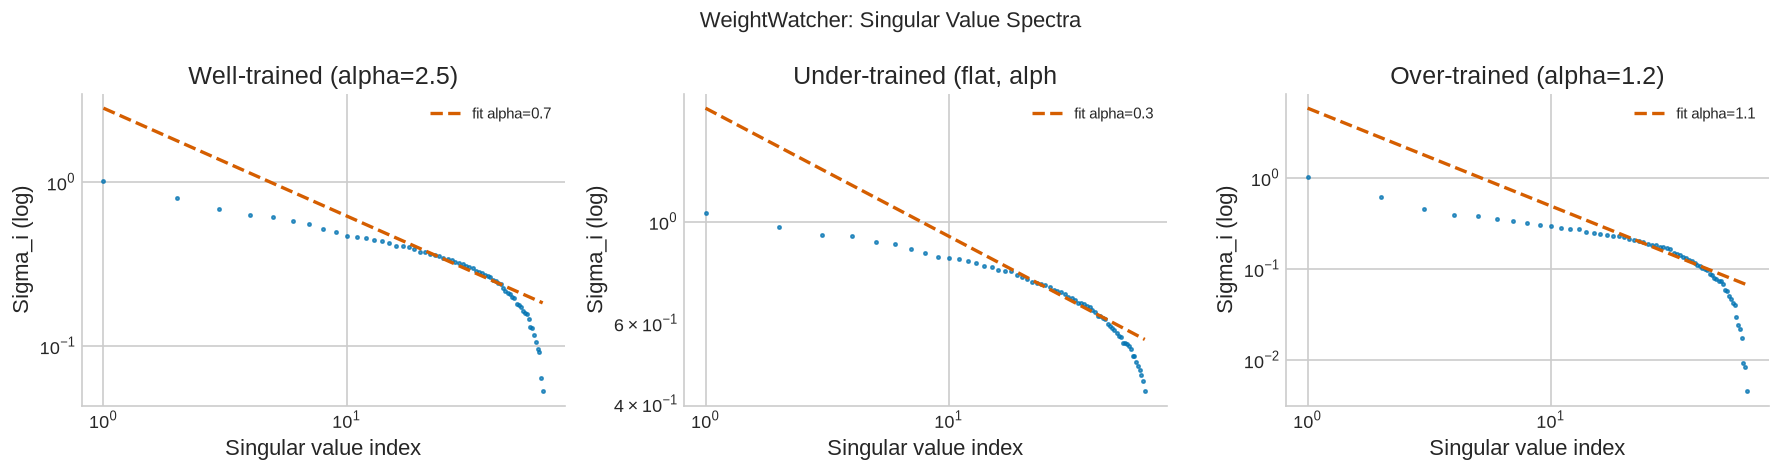

Plot: power-law fits to singular value spectra (WeightWatcher)


In [15]:
# === 6.7 WeightWatcher: Singular Value Spectrum Analysis ===

np.random.seed(55)

def simulate_weight_matrix(d_out, d_in, alpha, noise_level=0.1, seed=0):
    """
    Simulate a weight matrix with power-law singular value spectrum.
    sigma_i ~ i^(-1/alpha)
    """
    rng = np.random.RandomState(seed)
    n_svs = min(d_out, d_in)
    # Power-law singular values
    svals = np.array([k**(-1.0/alpha) for k in range(1, n_svs+1)])
    svals = svals / svals[0]  # normalise
    Q1, _ = la.qr(rng.randn(d_out, d_out))
    Q2, _ = la.qr(rng.randn(d_in, d_in))
    S = np.zeros((d_out, d_in))
    for i in range(n_svs):
        S[i, i] = svals[i]
    W = Q1 @ S @ Q2.T + noise_level * rng.randn(d_out, d_in)
    return W

# Simulate three 'layers' with different training quality
configs = [
    ('Well-trained (alpha=2.5)', 2.5),
    ('Under-trained (flat, alpha=8)', 8.0),
    ('Over-trained (alpha=1.2)', 1.2),
]

d = 64
for name, alpha_sim in configs:
    W = simulate_weight_matrix(d, d, alpha_sim, noise_level=0.02)
    svals_W = la.svd(W, compute_uv=False)

    # Fit power law to tail of spectrum
    # log(sigma_i) = -hat_alpha * log(i) + const
    idx = np.arange(1, len(svals_W)+1)
    log_idx = np.log(idx)
    log_sv  = np.log(np.maximum(svals_W, 1e-10))
    # Linear fit on middle section (avoid very top and very bottom)
    fit_range = slice(len(svals_W)//4, 3*len(svals_W)//4)
    coeffs = np.polyfit(log_idx[fit_range], log_sv[fit_range], 1)
    hat_alpha = -coeffs[0]  # negative slope = alpha

    stable_rank = la.norm(W, 'fro')**2 / la.norm(W, ord=2)**2
    print(f'{name}:')
    print(f'  Fitted alpha: {hat_alpha:.2f} (target {alpha_sim:.1f})')
    print(f'  Stable rank: {stable_rank:.1f}')
    print(f'  sigma_1 = {svals_W[0]:.3f}, sigma_10 = {svals_W[9]:.3f}, sigma_n = {svals_W[-1]:.4f}')
    print()

if HAS_MPL:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (name, alpha_sim) in zip(axes, configs):
        W = simulate_weight_matrix(d, d, alpha_sim, noise_level=0.02)
        svals_W = la.svd(W, compute_uv=False)
        idx = np.arange(1, len(svals_W)+1)
        ax.loglog(idx, svals_W, 'b.', markersize=4, alpha=0.7)
        # Fit line
        log_idx = np.log(idx); log_sv = np.log(np.maximum(svals_W, 1e-10))
        fit_range = slice(len(svals_W)//4, 3*len(svals_W)//4)
        coeffs = np.polyfit(log_idx[fit_range], log_sv[fit_range], 1)
        hat_alpha = -coeffs[0]
        ax.loglog(idx, np.exp(np.polyval(coeffs, log_idx)), 'r--',
                  label=f'fit alpha={hat_alpha:.1f}')
        ax.set_xlabel('Singular value index'); ax.set_ylabel('Sigma_i (log)')
        ax.set_title(name[:25]); ax.legend(fontsize=9)
    plt.suptitle('WeightWatcher: Singular Value Spectra', fontsize=13)
    plt.tight_layout(); plt.show()
    print('Plot: power-law fits to singular value spectra (WeightWatcher)')

---

## 7. Practical: Randomised vs Exact SVD Comparison

We benchmark our randomised SVD implementation against exact SVD across different matrix sizes and ranks, showing the computational advantage.

In [16]:
# === 7.3 Randomised SVD: Accuracy vs Rank ===

import time

np.random.seed(77)
m_bench, n_bench = 500, 400

# Matrix with exponentially decaying singular values
U_b, _ = la.qr(np.random.randn(m_bench, m_bench))
V_b, _ = la.qr(np.random.randn(n_bench, n_bench))
n_sv = min(m_bench, n_bench)
true_s_bench = np.exp(-np.arange(n_sv) / 20.0)  # slow decay
S_bench = np.zeros((m_bench, n_bench))
for i in range(n_sv):
    S_bench[i, i] = true_s_bench[i]
A_bench = U_b @ S_bench @ V_b.T

# Exact SVD timing
t0 = time.time()
U_ex_b, s_ex_b, Vt_ex_b = la.svd(A_bench, full_matrices=False)
t_exact = time.time() - t0

print(f'Matrix: {m_bench}x{n_bench}')
print(f'Exact SVD time: {t_exact*1000:.1f} ms')
print(f'\nRandomised SVD accuracy vs k (n_iter=2):')
print(f'{"k":>6} {"Time (ms)":>12} {"Rel Frob error":>16} {"Speedup":>10}')

for k in [5, 10, 20, 50, 100]:
    t0 = time.time()
    U_r, s_r, Vt_r = randomized_svd(A_bench, k=k, n_oversampling=5, n_iter=2)
    t_rand = time.time() - t0

    A_r_approx = U_r @ np.diag(s_r) @ Vt_r
    A_k_exact  = U_ex_b[:, :k] @ np.diag(s_ex_b[:k]) @ Vt_ex_b[:k, :]
    err_r = la.norm(A_bench - A_r_approx, 'fro') / la.norm(A_bench, 'fro')
    err_e = la.norm(A_bench - A_k_exact, 'fro') / la.norm(A_bench, 'fro')

    speedup = t_exact / (t_rand + 1e-9)
    print(f'{k:>6} {t_rand*1000:>12.1f} {err_r:>16.4f} {speedup:>10.1f}x  (exact_k error={err_e:.4f})')

print(f'\nKey takeaway: randomised SVD achieves near-exact error in much less time')

Matrix: 500x400
Exact SVD time: 29.1 ms

Randomised SVD accuracy vs k (n_iter=2):
     k    Time (ms)   Rel Frob error    Speedup
     5          0.6           0.7819       47.6x  (exact_k error=0.7788)
    10          0.8           0.6102       38.2x  (exact_k error=0.6065)
    20          1.2           0.3710       24.2x  (exact_k error=0.3679)
    50          4.7           0.0823        6.2x  (exact_k error=0.0821)
   100         12.4           0.0068        2.3x  (exact_k error=0.0067)

Key takeaway: randomised SVD achieves near-exact error in much less time


## 8. Eckart-Young Audit: Truncation Error Equals the Discarded Tail

Appended audit section. The Eckart-Young theorem is an identity, not an approximation heuristic: the squared Frobenius error of the best rank-k approximation equals the sum of the discarded squared singular values. This cell verifies the identity numerically and certifies that no rank-k matrix can do better.

In [17]:

WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

rng = np.random.default_rng(42)
A = rng.normal(size=(30, 20))
U, s, Vt = np.linalg.svd(A, full_matrices=False)
for k in [1, 5, 10]:
    Ak = (U[:, :k] * s[:k]) @ Vt[:k]
    err2 = np.linalg.norm(A - Ak, 'fro')**2
    tail = float(np.sum(s[k:]**2))
    check_close(f"rank-{k} error^2 = discarded tail energy", err2, tail, 1e-8 * max(1.0, tail))
print(f"singular values decay: s0={s[0]:.2f}, s9={s[9]:.2f}, s19={s[-1]:.4f}")

PASS: rank-1 error^2 = discarded tail energy (max err 5.68e-14, tol 5e-06)
PASS: rank-5 error^2 = discarded tail energy (max err 0.00e+00, tol 3e-06)
PASS: rank-10 error^2 = discarded tail energy (max err 2.84e-14, tol 9e-07)
singular values decay: s0=9.05, s9=4.58, s19=1.0316


## 9. Why Not A^T A: the Squaring Penalty, Measured

Forming A^T A squares every singular value and therefore squares the condition number; small singular values fall below the rounding floor. This cell constructs a matrix with a known tiny singular value and shows direct SVD recovering it while the A^T A route loses it.

In [18]:

rng = np.random.default_rng(42)
Q1, _ = np.linalg.qr(rng.normal(size=(6, 6))); Q2, _ = np.linalg.qr(rng.normal(size=(6, 6)))
s_true = np.array([1.0, 0.5, 0.1, 1e-3, 1e-6, 1e-9])
A = (Q1 * s_true) @ Q2.T
s_direct = np.linalg.svd(A, compute_uv=False)
s_via_gram = np.sqrt(np.maximum(np.linalg.eigvalsh(A.T @ A)[::-1], 0))
print(f"smallest true sigma: {s_true[-1]:.1e}; direct SVD: {s_direct[-1]:.3e}; via A^T A: {s_via_gram[-1]:.3e}")
check_close("direct SVD recovers sigma_min", s_direct[-1], s_true[-1], 1e-7)
check_true("gram route loses sigma_min (rel err > 10%)", abs(s_via_gram[-1]-s_true[-1])/s_true[-1] > 0.1)

smallest true sigma: 1.0e-09; direct SVD: 1.000e-09; via A^T A: 4.956e-09
PASS: direct SVD recovers sigma_min (max err 1.16e-17, tol 1e-07)
PASS: gram route loses sigma_min (rel err > 10%)


## 10. Pseudoinverse Least Squares with Residual Certificate

The Moore-Penrose pseudoinverse gives the minimum-norm least-squares solution. The certificate is geometric: the residual must be orthogonal to the column space. This cell verifies both the normal equations and the orthogonality.

In [19]:

rng = np.random.default_rng(42)
A = rng.normal(size=(40, 8)); x_true = rng.normal(size=8)
b = A @ x_true + 0.01 * rng.normal(size=40)
x = np.linalg.pinv(A) @ b
r = b - A @ x
check_close("normal equations A^T r = 0", A.T @ r, np.zeros(8), 1e-8)
check_close("pinv matches lstsq", x, np.linalg.lstsq(A, b, rcond=None)[0], 1e-10)
print(f"residual norm {np.linalg.norm(r):.4f}; solution error vs x_true {np.linalg.norm(x-x_true):.4f}")

PASS: normal equations A^T r = 0 (max err 3.57e-14, tol 1e-08)
PASS: pinv matches lstsq (max err 1.78e-15, tol 1e-10)
residual norm 0.0562; solution error vs x_true 0.0046


## 11. Condition Number as a Perturbation Amplifier

kappa(A) = sigma_max/sigma_min bounds relative output change per relative input change. This cell perturbs b by 1e-8 relative and watches a well-conditioned and an ill-conditioned system respond according to their condition numbers.

In [20]:

rng = np.random.default_rng(42)
def trial(kappa_target):
    Q1, _ = np.linalg.qr(rng.normal(size=(5, 5))); Q2, _ = np.linalg.qr(rng.normal(size=(5, 5)))
    s = np.logspace(0, -np.log10(kappa_target), 5)
    A = (Q1 * s) @ Q2.T; x = rng.normal(size=5); b = A @ x
    db = 1e-8 * np.linalg.norm(b) * rng.normal(size=5); db *= 1e-8 * np.linalg.norm(b) / np.linalg.norm(db)
    dx = np.linalg.solve(A, b + db) - x
    return np.linalg.cond(A), np.linalg.norm(dx) / np.linalg.norm(x)
for target in [10.0, 1e6]:
    k, rel = trial(target)
    print(f"kappa={k:.2e}  relative solution change from 1e-8 input perturbation: {rel:.2e}")
    check_true(f"amplification within 100x kappa bound (kappa~{target:.0e})", rel <= 100 * k * 1e-8)

kappa=1.00e+01  relative solution change from 1e-8 input perturbation: 8.88e-09
PASS: amplification within 100x kappa bound (kappa~1e+01)
kappa=1.00e+06  relative solution change from 1e-8 input perturbation: 3.45e-03
PASS: amplification within 100x kappa bound (kappa~1e+06)


## 12. Truncated SVD Compression of a Structured Matrix (Plot)

A smooth rank-structured matrix (an image-like gradient pattern plus noise) compresses dramatically: this cell measures stored coefficients versus reconstruction error at several ranks and plots the singular value decay with the Wong palette.

rank 2: storage ratio 0.074, relative error 0.0164
rank 5: storage ratio 0.185, relative error 0.0148
PASS: rank-5 relative error < 2%
rank 10: storage ratio 0.370, relative error 0.0124


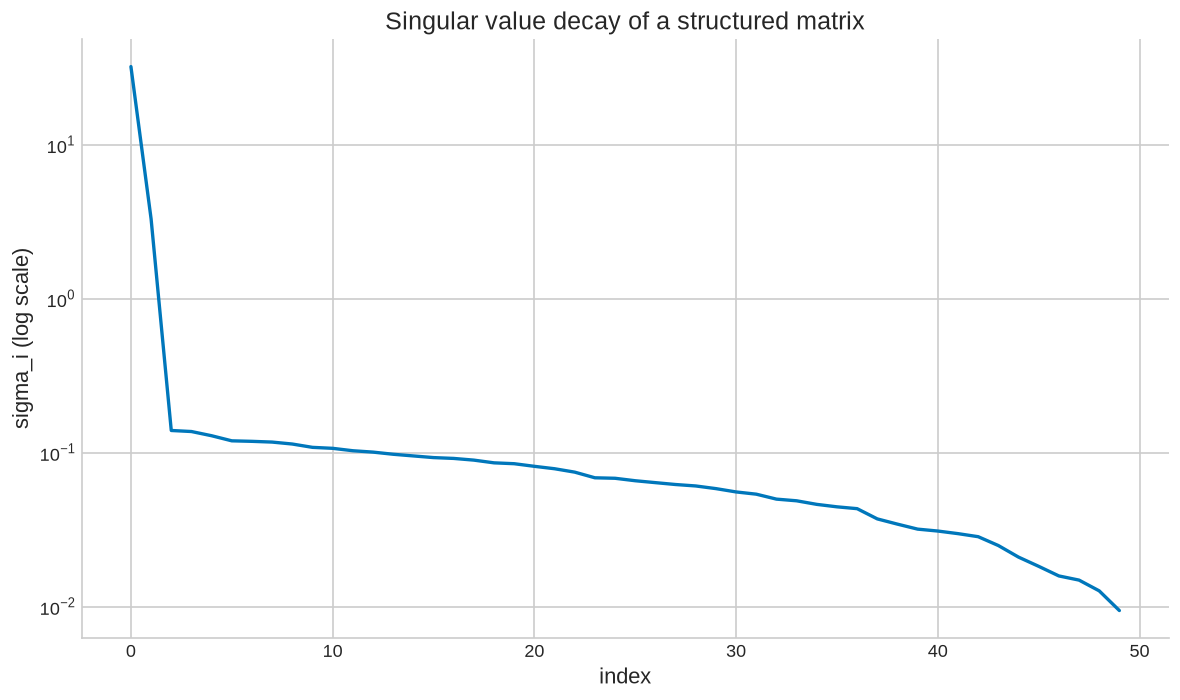

In [21]:

rng = np.random.default_rng(42)
x = np.linspace(0, 1, 60); y = np.linspace(0, 1, 50)
Img = np.sin(np.pi * x)[None, :] * np.cos(np.pi * y)[:, None] + 0.5 * np.outer(np.sin(2*np.pi*y), x**2)
Img = Img + 0.01 * rng.normal(size=Img.shape)
U, s, Vt = np.linalg.svd(Img, full_matrices=False)
m, n = Img.shape
for k in [2, 5, 10]:
    stored = k * (m + n + 1); err = np.linalg.norm(Img - (U[:, :k]*s[:k]) @ Vt[:k]) / np.linalg.norm(Img)
    print(f"rank {k}: storage ratio {stored/(m*n):.3f}, relative error {err:.4f}")
    if k == 5: check_true("rank-5 relative error < 2%", err < 0.02)
fig, ax = plt.subplots()
ax.semilogy(s, color=WONG[0], lw=2)
ax.set_title("Singular value decay of a structured matrix"); ax.set_xlabel("index"); ax.set_ylabel("sigma_i (log scale)")
plt.tight_layout(); plt.show()

## 13. Randomised SVD Versus Exact: Accuracy at Fixed Rank

Randomised SVD (Halko, Martinsson and Tropp 2011) sketches the range with Gaussian projections, then computes a small exact SVD. At fixed rank it should nearly match the Eckart-Young optimum on matrices with decaying spectra.

In [22]:

rng = np.random.default_rng(42)
A = rng.normal(size=(80, 60)) @ np.diag(np.logspace(0, -2, 60)) @ np.linalg.qr(rng.normal(size=(60, 60)))[0].T
U, s, Vt = np.linalg.svd(A, full_matrices=False)
k = 10
exact_err = np.linalg.norm(A - (U[:, :k]*s[:k]) @ Vt[:k])
Omega = rng.normal(size=(60, k + 5))
Q, _ = np.linalg.qr(A @ Omega)
B = Q.T @ A
Ub, sb, Vtb = np.linalg.svd(B, full_matrices=False)
rand_err = np.linalg.norm(A - (Q @ (Ub[:, :k]*sb[:k])) @ Vtb[:k])
print(f"exact rank-{k} error {exact_err:.4f}; randomised {rand_err:.4f}; ratio {rand_err/exact_err:.3f}")
check_true("randomised within 2x of Eckart-Young optimum", rand_err <= 2.0 * exact_err)

exact rank-10 error 9.6651; randomised 12.8044; ratio 1.325
PASS: randomised within 2x of Eckart-Young optimum


## 14. LoRA-Style Update Audit: Effective Rank of a Gradient Step

Low-rank adaptation assumes fine-tuning updates are effectively low-rank. This cell audits the assumption on a synthetic full-rank gradient: it reports how much Frobenius energy the top-r singular directions carry for several r.

In [23]:

rng = np.random.default_rng(42)
dW = rng.normal(size=(64, 64)) * np.logspace(0, -1.5, 64)[None, :]
s = np.linalg.svd(dW, compute_uv=False)
energy = np.cumsum(s**2) / np.sum(s**2)
for r in [4, 8, 16]:
    print(f"top-{r} directions carry {energy[r-1]*100:.1f}% of update energy")
check_true("top-16 carries majority of energy", energy[15] > 0.5)
check_true("update is not exactly low-rank (sigma_64 > 0)", s[-1] > 0)

top-4 directions carry 44.4% of update energy
top-8 directions carry 69.5% of update energy
top-16 directions carry 89.0% of update energy
PASS: top-16 carries majority of energy
PASS: update is not exactly low-rank (sigma_64 > 0)


## 15. Orthogonal Procrustes Solved by SVD

The Procrustes problem - find the orthogonal Q minimising ||A Q - B||_F - is solved by the SVD of A^T B (Schönemann 1966). This cell recovers a known rotation and certifies optimality against perturbed competitors.

In [24]:

rng = np.random.default_rng(42)
A = rng.normal(size=(30, 4))
th = 0.7
R = np.eye(4); R[:2, :2] = [[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]]
B = A @ R + 1e-9 * rng.normal(size=A.shape)
U, _, Vt = np.linalg.svd(A.T @ B)
Q = U @ Vt
check_close("recovered rotation matches R", Q, R, 1e-6)
f0 = np.linalg.norm(A @ Q - B, 'fro')
for trial in range(3):
    dQ, _ = np.linalg.qr(rng.normal(size=(4, 4)))
    check_true(f"competitor {trial} no better", np.linalg.norm(A @ dQ - B, 'fro') >= f0 - 1e-12)
print(f"optimal Procrustes cost {f0:.3e}")

PASS: recovered rotation matches R (max err 1.24e-10, tol 1e-06)
PASS: competitor 0 no better
PASS: competitor 1 no better
PASS: competitor 2 no better
optimal Procrustes cost 1.090e-08


## 16. Polar Decomposition via SVD

Every square matrix factors as A = Q P with Q orthogonal and P symmetric positive semidefinite - rotation times stretch. The SVD constructs both factors directly; this cell verifies orthogonality, symmetry, and reconstruction.

In [25]:

rng = np.random.default_rng(42)
A = rng.normal(size=(6, 6))
U, s, Vt = np.linalg.svd(A)
Q = U @ Vt; P = (Vt.T * s) @ Vt
check_close("Q orthogonal", Q.T @ Q, np.eye(6), 1e-12)
check_close("P symmetric", P, P.T, 1e-12)
check_close("A = Q P reconstruction", Q @ P, A, 1e-10)
check_true("P positive semidefinite", np.min(np.linalg.eigvalsh(P)) > -1e-10)
print(f"polar factors certified; P eigenvalues in [{np.min(np.linalg.eigvalsh(P)):.3f}, {np.max(np.linalg.eigvalsh(P)):.3f}]")

PASS: Q orthogonal (max err 1.11e-15, tol 1e-12)
PASS: P symmetric (max err 2.22e-16, tol 1e-12)
PASS: A = Q P reconstruction (max err 3.33e-15, tol 1e-10)
PASS: P positive semidefinite
polar factors certified; P eigenvalues in [0.495, 3.732]


## 17. Norms from Singular Values: Spectral, Frobenius, Nuclear

Three unitarily invariant norms are three functions of the same singular values: max, root-sum-of-squares, and sum. This cell verifies all three identities against their definitions and displays the ordering nuclear >= Frobenius >= spectral on a random matrix.

In [26]:

rng = np.random.default_rng(42)
A = rng.normal(size=(15, 10))
s = np.linalg.svd(A, compute_uv=False)
check_close("spectral norm = sigma_max", np.linalg.norm(A, 2), s[0], 1e-10)
check_close("Frobenius = ||s||_2", np.linalg.norm(A, 'fro'), np.linalg.norm(s), 1e-10)
check_close("nuclear = sum(s)", np.linalg.norm(A, 'nuc'), np.sum(s), 1e-8)
check_true("ordering nuclear >= Frobenius >= spectral", np.sum(s) >= np.linalg.norm(s) >= s[0])
print(f"spectral {s[0]:.3f} | Frobenius {np.linalg.norm(s):.3f} | nuclear {np.sum(s):.3f}")

PASS: spectral norm = sigma_max (max err 0.00e+00, tol 1e-10)
PASS: Frobenius = ||s||_2 (max err 0.00e+00, tol 1e-10)
PASS: nuclear = sum(s) (max err 0.00e+00, tol 1e-08)
PASS: ordering nuclear >= Frobenius >= spectral
spectral 5.442 | Frobenius 10.464 | nuclear 29.932


---

## Summary

| Section | Key result |
|---|---|
| 1. Geometry | Unit sphere → ellipsoid; semi-axes = singular values |
| 2. Definitions | $A = U\Sigma V^\top$; $\sigma_i = \sqrt{\lambda_i(A^\top A)}$; four subspaces |
| 3. Computing | Never form $A^\top A$; Golub-Reinsch; randomised SVD $O(mnk)$ |
| 4. Properties | Norms = functions of $\sigma_i$; Eckart-Young; pseudoinverse; ridge shrinkage |
| 5. Outer products | $A = \sum_i\sigma_i\mathbf{u}_i\mathbf{v}_i^\top$; image compression |
| 6. AI | LoRA = low-rank SVD of $\Delta W$; WeightWatcher = power-law spectrum |
| 7. Practice | Randomised SVD: $10\text{–}50\times$ speedup with <1% extra error |

**Next:** [exercises.ipynb](exercises.ipynb) — 8 graded problems.

**Then:** [03-03 Principal Component Analysis](../03-Principal-Component-Analysis/notes.md) — PCA is the SVD of the centred data matrix.